In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import PretrainedConfig, PreTrainedModel, GenerationMixin


class MiniMindConfig(PretrainedConfig):
    model_type = "minimind"
    def __init__(self, hidden_size=768, num_hidden_layers=8, use_moe=False, **kwargs):
        super().__init__(**kwargs)
        self.hidden_size = hidden_size
        self.num_hidden_layers = num_hidden_layers
        self.use_moe = use_moe
        self.dropout = kwargs.get("dropout", 0.0)
        self.vocab_size = kwargs.get("vocab_size", 6400)
        self.bos_token_id = kwargs.get("bos_token_id", 1)
        self.eos_token_id = kwargs.get("eos_token_id", 2)
        self.flash_attn = kwargs.get("flash_attn", True)
        self.num_attention_heads = kwargs.get("num_attention_heads", 8)
        self.num_key_value_heads = kwargs.get("num_key_value_heads", 4)
        self.head_dim = kwargs.get("head_dim", self.hidden_size // self.num_attention_heads)
        self.hidden_act = kwargs.get("hidden_act", 'silu')
        self.intermediate_size = kwargs.get("intermediate_size", math.ceil(hidden_size * math.pi / 64) * 64)
        self.max_position_embeddings = kwargs.get("max_position_embeddings", 32768)
        self.rms_norm_eps = kwargs.get("rms_norm_eps", 1e-6)
        self.rope_theta = kwargs.get("rope_theta", 1e6)
        self.tie_word_embeddings = kwargs.get("tie_word_embeddings", True)
        self.inference_rope_scaling = kwargs.get("inference_rope_scaling", False)
        self.rope_scaling = {
            "beta_fast": 32,
            "beta_slow": 1,
            "factor": 16,
            "original_max_position_embeddings": 2048,
            "attention_factor": 1.0,
            "type": "yarn"
        } if self.inference_rope_scaling else None
        ### MoE specific configs (ignored if use_moe = False)
        self.num_experts = kwargs.get("num_experts", 4)
        self.num_experts_per_tok = kwargs.get("num_experts_per_tok", 1)
        self.moe_intermediate_size = kwargs.get("moe_intermediate_size", self.intermediate_size)
        self.norm_topk_prob = kwargs.get("norm_topk_prob", True)
        self.router_aux_loss_coef = kwargs.get("router_aux_loss_coef", 5e-4)




FFN:这里就是使用一个silu

In [3]:
class FeedForward(nn.Module):
    def __init__(self, config: MiniMindConfig, intermediate_size: int = None):
        super().__init__()
        intermediate_size = intermediate_size or config.intermediate_size
        self.gate_proj = nn.Linear(config.hidden_size, intermediate_size, bias=False)
        self.up_proj = nn.Linear(config.hidden_size, intermediate_size, bias=False)
        self.down_proj = nn.Linear(intermediate_size, config.hidden_size, bias=False)
        self.act_fn = ACT2FN[config.hidden_act]

    def forward(self, x):
        return self.down_proj(self.act_fn(self.gate_proj(x)) * self.up_proj(x))

MOE:

In [1]:
# 创建一个随机的二维张量
import torch
x = torch.randint(1, 100, (4, 5))
print("Original matrix:\n", x)

# 在第一个维度上找到每列的最大的2个元素
values, indices = torch.topk(x, 2, dim=0, largest=True)
print("Top 2 values in each column:\n", values)
print("Indices of top 2 values in each column:\n", indices)

Original matrix:
 tensor([[82,  6,  4, 80, 78],
        [87, 76, 35, 21, 91],
        [95, 41, 48, 72, 54],
        [89, 94, 68, 50, 90]])
Top 2 values in each column:
 tensor([[95, 94, 68, 80, 91],
        [89, 76, 48, 72, 90]])
Indices of top 2 values in each column:
 tensor([[2, 3, 3, 0, 1],
        [3, 1, 2, 2, 3]])


In [ ]:
class MOEFeedForward(nn.Module):
    def __init__(self, config: MiniMindConfig):
        super().__init__()
        self.config = config
        # 768 -> 4
        self.gate = nn.Linear(config.hidden_size, config.num_experts, bias=False)
        # 给4的专家都生成一个FFN前馈神经网络
        self.experts = nn.ModuleList([FeedForward(config, intermediate_size=self.config.moe_intermediate_size) for _ in range(config.num_experts)])

    def forward(self, x):
        # x 形状为 [bs, seq_len, hidden_dim]
        # 举个荔枝 [32, 64, 768]
        batch_size, seq_len, hidden_dim = x.shape
        # x_flat -> [bs*seq_len, hidden_dim]
        # 举个荔枝 [32*64, 768] = [2048, 768]
        x_flat = x.reshape(-1, hidden_dim) # [N, H]
        # self.gate(x_flat) -> [bs*seq_len, hidden_dim] -> [N, num_experts] 然后在对num_experts维度做softmax
        #                      [2048, 768]              -> [2048, 4]
        scores = F.softmax(self.gate(x_flat), dim=-1) # [N, num_experts] 表示每个 token 对应的 num_experts 的分数
        # k = num_experts_per_tok = 2 [N, num_experts]就是对num_experts这个中取概率最大的两个
        # k = 2                       topk_weight = [2048, 2] 这个中的2是对应的softmax的概率 topk_idx = [2048, 2] 这个中的2是对应的专家索引号
        topk_weight, topk_idx = torch.topk(scores, k=self.config.num_experts_per_tok, dim=-1, sorted=False) # [N, K]
        # 对 topk_weight 进行归一化 由于你取出来的是4个专家的saftmax概率，现在取softmax概率是两个（k）之间的
        # topk_weight = [2048, 2]
        if self.config.norm_topk_prob:
            if self.config.num_experts_per_tok > 1:
                # 直接 除 sum 进行归一化
                topk_weight = topk_weight / (topk_weight.sum(dim=-1, keepdim=True) + 1e-20)
            else:
                # 我们不能直接设置 topk_weight = 1, 因为这样不能进入计算图中参与更新, 所以我们使用STE
                # 这里和源码不同, 我直接让topk_weight 也参与上游计算了, 保证和 K > 1 分支一致
                topk_weight = topk_weight - topk_weight.detach() + 1.0 # 前向时是 1.0, 反向传播的时候那个 detach() 会从计算图分离出来, 也是 1.0 * 从上游来的梯度
        # 创建一张和x_flat = [bs*seq_len, hidden_dim]一样的全0特征维度的特征表
        y = torch.zeros_like(x_flat)
        # 遍历每个专家, 对每个专家, 查看激活他的 token 并输送到这个 expert 中获取输出加到 y 对应行上
        # 走一个循环，比如专家1，eg.: topk_idx [6,2] topk_weight = [6,2]  N=6 个 token，K=2，Experts=4 个专家，hidden_size=3
        for i, expert in enumerate(self.experts):
            #topk_idx [6,2]:                                     topk_weight [6,2]: 每行和为 1（已归一化）  
            # token0: [1, 0]     ← 第0格去专家1,第1格去专家0       token0: [0.60, 0.40]                       token0: [1, 0] -> [ True, False]
            # token1: [0, 1]                                      token1: [0.55, 0.45]                        token1: [0, 1] -> [False,  True]
            # token2: [1, 2]                                      token2: [0.70, 0.30]                        token2: [1, 2] -> [ True, False]
            # token3: [3, 0]                                      token3: [0.80, 0.20]                        token3: [3, 0] -> [False, False]     ← token3 没选专家1
            # token4: [1, 3]                                      token4: [0.50, 0.50]                        token4: [1, 3] -> [ True, False]
            # token5: [2, 1]                                      token5: [0.50, 0.50]                        token5: [2, 1] -> [False,  True]
            mask = (topk_idx == i) # (N, k) , 为 True 表示当前这个 token 使用了 i 专家

            if mask.any(): # 说明这个 i 专家被使用过
                # 找到使用这个 i 专家的 token_idx, mask.any(dim=-1) 形状为 (N, ), 表示每一行有没有一个 T,  nonzero() 形状为 (m, 1) 取出为 T 的行的 id, flatten() 展平成 (m, ) 表示用到 i 专家的 token_id 组成的tensor
                # mask.any(dim=-1) 把 K 这一维"吞掉"：只要这一行有任何一个 True，就是 True。[True, True, True, False, True, True]
                #                                                                                               ↑ token3 是 False（它没选专家1）
                # .nonzero().flatten() 返回的是哪几个token选择了专家1 ：token_idx = [0, 1, 2, 4, 5]     形状 (5,) token3它没选专家1
                token_idx = mask.any(dim=-1).nonzero().flatten()
                # topk_weight[mask] 为一维张量, 取出对应 True 的对应权重, 形状为 (m, )
                # 取所有 True 的格子 → weight = [[0.60, 0.45, 0.70, 0.50, 0.35]]     形状 (5,1) 每个token选择专家1所对应的概率
                weight = topk_weight[mask].view(-1, 1)
                # source=(expert(x_flat[token_idx]) * weight).to(y.dtype) 就是取出x_flat = [6, hidden_dim] 对应的token_idx = [0, 1, 2, 4, 5] 的5行经过专家1然后乘以对应的weight = [[0.60, 0.45, 0.70, 0.50, 0.35]]
                # y.index_add_就是把这次的结果写回去对应维度上面去
                # y[0] = [-1.35, -1.38,  0.68]  ← 专家1 写的
                # y[1] = [ 0.71,  0.54, -1.40]  ← 专家1 写的
                # y[2] = [-0.48,  2.59,  0.66]  ← 专家1 写的
                # y[3] = [ 0.00,  0.00,  0.00]  ← token3 没选专家1，还是 0
                # y[4] = [ 1.39,  1.59,  0.95]  ← 专家1 写的
                # y[5] = [-0.59,  0.65,  0.88]  ← 专家1 写的
                # 此时y.shape = [N, hidden_size]
                y.index_add_(dim=0, index=token_idx, source=(expert(x_flat[token_idx]) * weight).to(y.dtype))
            elif self.training:
                y[0, 0] += 0.0 * sum((p.sum() for p in expert.parameters()))

        # 用于训练时计算辅助损失函数 auxiliary_loss
        if self.training and self.config.router_aux_loss_coef > 0:
            # 计算每个专家实际激活 token 的比例 (实际负载), 这里 counts 会产生一个 max(max(topk_idx) + 1, minlength) -> 也就是 num_experts 长度的一维张量, 每个 id 下标对应的是实际的在 topk_idx 中的出现次数
            counts = torch.bincount(topk_idx.flatten(), minlength=self.config.num_experts)
            # 归一化计算出比例 (每个数表示当前专家实际处理的 token 数 / 总 token 数)
            f = counts / topk_idx.numel()
            # scores.mean(0) 形状为 (num_experts, ) , 表示门控认为应该给对应专家的平均概率 (有梯度)
            self.aux_loss = (scores.mean(0) * f).sum() * self.config.num_experts * self.config.router_aux_loss_coef # 给类注册一个属性, 后续能通过实例. 访问到
        else:
            # 推理时直接设 0 即可
            self.aux_loss = scores.new_zeros(1).squeeze() # 设为标量保证和前面一致
        # [N, hidden_size] -> [bs, seq_len, hidden_dim]
        # [2048, 768]      -> [[32, 64, 768]]
        y = y.view(batch_size, seq_len, hidden_dim)
        return y

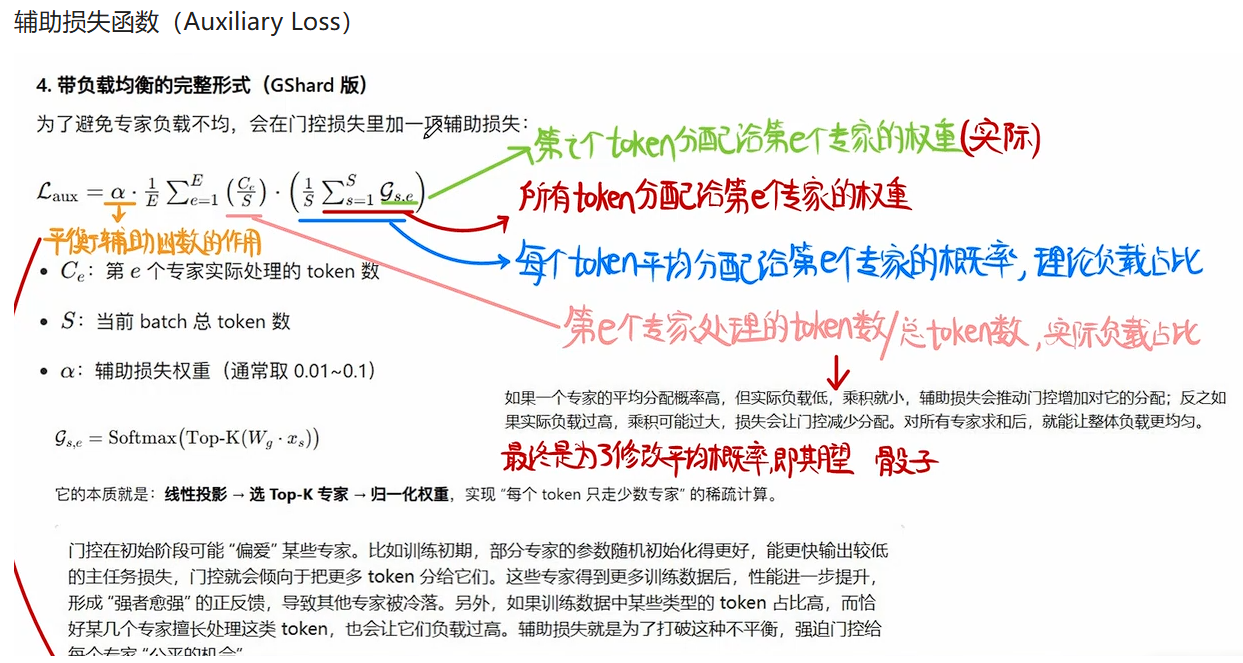